In [4]:
!pip install torch
!pip install avalanche-lib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 993.4/993.4 kB 68.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 132.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 116.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 585.2/585.2 kB 39.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 90.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 67.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 836.9/836.9 kB 23.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 55.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 83.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 MB 74.4 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 48.6 MB/s  0:00:00
   ━━━━

In [13]:
import sys, os
sys.path.append(os.path.abspath(".."))

In [16]:
import torch
import pandas as pd

from IPython.display import display

from avalanche.benchmarks.classic import SplitMNIST, SplitCIFAR10
from avalanche.training.supervised import Naive
from torch.optim import SGD
from torch.nn import CrossEntropyLoss

from models.model_factory import build_model
from experiments.eval_plugin_factory import build_eval_plugin

from analysis.metrics import analyze_single_experiment
from analysis.plots import plot_single_experiment

In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


/opt/conda/lib/python3.10/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [18]:
benchmark_name = "splitmnist"

if benchmark_name == "splitmnist":
    benchmark = SplitMNIST(
        n_experiences=5,
        return_task_id=True,
        seed=42
    )
elif benchmark_name == "splitcifar10":
    benchmark = SplitCIFAR10(
        n_experiences=5,
        return_task_id=True,
        seed=42
    )
else:
    raise ValueError(f"Unknown benchmark: {benchmark_name}")

print("Benchmark created")
print("Number of classes:", benchmark.n_classes)
print("Number of train experiences:", len(benchmark.train_stream))
print("Number of test experiences:", len(benchmark.test_stream))

100%|██████████| 9.91M/9.91M [00:00<00:00, 132MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 9.94MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 37.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.58MB/s]


Benchmark created
Number of classes: 10
Number of train experiences: 5
Number of test experiences: 5


In [19]:
for exp in benchmark.train_stream:
    print(f"Experience {exp.current_experience}")
    print("Classes in this experience:", exp.classes_in_this_experience)
    print("Task labels:", exp.task_labels)
    print("-" * 50)

Experience 0
Classes in this experience: [2, 6]
Task labels: [0]
--------------------------------------------------
Experience 1
Classes in this experience: [8, 1]
Task labels: [1]
--------------------------------------------------
Experience 2
Classes in this experience: [4, 5]
Task labels: [2]
--------------------------------------------------
Experience 3
Classes in this experience: [0, 9]
Task labels: [3]
--------------------------------------------------
Experience 4
Classes in this experience: [3, 7]
Task labels: [4]
--------------------------------------------------


In [21]:
model_name = "avalanche_simplemlp"

model = build_model(
    model_name=model_name,
    input_size=28 * 28,
    hidden_size=256,
    hidden_layers=2,
    num_classes=benchmark.n_classes
)

print(model)

SimpleMLP(
  (features): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.5, inplace=False)
    (3): Sequential(
      (0): Linear(in_features=256, out_features=256, bias=True)
      (1): ReLU(inplace=True)
      (2): Dropout(p=0.5, inplace=False)
    )
  )
  (classifier): Linear(in_features=256, out_features=10, bias=True)
)


In [22]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 269322
Trainable parameters: 269322


In [23]:
output_dir = "outputs/test_pipeline_run"
print("Output dir:", output_dir)

Output dir: outputs/test_pipeline_run


In [24]:
eval_plugin, log_file_handle = build_eval_plugin(
    output_dir=output_dir,
    num_classes=benchmark.n_classes,
    enable_tensorboard=True,
    enable_text_logging=True,
    enable_interactive_logging=True,
    save_confusion_matrix=False,
)

print("Evaluation plugin created")

Evaluation plugin created


In [27]:
optimizer = SGD(model.parameters(), lr=0.01)
criterion = CrossEntropyLoss()

cl_strategy = Naive(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    train_mb_size=32,
    train_epochs=1,
    eval_mb_size=32,
    evaluator=eval_plugin,
    device=device,
    eval_every=0
)

print("Strategy created:", cl_strategy)

Strategy created: <avalanche.training.supervised.strategy_wrappers.Naive object at 0x7f7419ed1270>


In [28]:
results = []

print("\nStarting continual learning experiment...\n")

for exp in benchmark.train_stream:
    print("=" * 70)
    print(f"Start of experience {exp.current_experience}")
    print("Classes:", exp.classes_in_this_experience)
    print("=" * 70)

    cl_strategy.train(exp)
    print(f"Training completed for experience {exp.current_experience}")

    res = cl_strategy.eval(benchmark.test_stream)
    results.append(res)

print("\nExperiment completed.")
print("Number of result dictionaries collected:", len(results))


Starting continual learning experiment...

Start of experience 0
Classes: [2, 6]
-- >> Start of training phase << --
-- >> Start of eval phase << --
-- Starting eval on experience 0 (Task 0) from train stream --
100%|██████████| 372/372 [00:04<00:00, 79.54it/s]
> Eval on experience 0 (Task 0) from train stream ended.
	CPUUsage_Exp/eval_phase/train_stream/Task000/Exp000 = 180.1156
	DiskUsage_Exp/eval_phase/train_stream/Task000/Exp000 = 123.3428
	Loss_Exp/eval_phase/train_stream/Task000/Exp000 = 0.0725
	Loss_Stream/eval_phase/test_stream/Task004 = 5.7038
	StreamBWT/eval_phase/test_stream = 0.0000
	StreamForgetting/eval_phase/test_stream = 0.0000
	Top1_Acc_Exp/eval_phase/train_stream/Task000/Exp000 = 0.9736
	Top1_Acc_Stream/eval_phase/test_stream/Task004 = 0.1944
-- >> End of eval phase << --
	ConfusionMatrix_Stream/eval_phase/train_stream = 
tensor([[   0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
        [   0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
       

In [29]:
if log_file_handle is not None:
    log_file_handle.close()
    print("Closed text log file handle.")

Closed text log file handle.



BUILDING SINGLE-EXPERIMENT ANALYSIS

Created results dataframe.
Number of rows (experiences): 5
Number of columns (metrics):  41

Columns found:
  - experience
  - train_time_epoch
  - test_acc_Exp000
  - test_loss_Exp000
  - cpu_usage_Exp000
  - test_disk_Exp000
  - test_acc_Exp001
  - test_loss_Exp001
  - cpu_usage_Exp001
  - test_disk_Exp001
  - test_acc_Exp002
  - test_loss_Exp002
  - cpu_usage_Exp002
  - test_disk_Exp002
  - test_acc_Exp003
  - test_loss_Exp003
  - cpu_usage_Exp003
  - test_disk_Exp003
  - test_acc_Exp004
  - test_loss_Exp004
  - cpu_usage_Exp004
  - test_disk_Exp004
  - test_acc_stream
  - test_loss_stream
  - Forgetting_stream
  - BWT_stream
  - FWT_Exp001
  - FWT_stream
  - test_disk_stream
  - confusion_matrix
  - Forgetting_Exp000
  - BWT_Exp000
  - FWT_Exp002
  - Forgetting_Exp001
  - BWT_Exp001
  - FWT_Exp003
  - Forgetting_Exp002
  - BWT_Exp002
  - FWT_Exp004
  - Forgetting_Exp003
  - BWT_Exp003

================ METRIC MEANINGS ================

Experien

,experience,train_time_epoch,test_acc_Exp000,test_loss_Exp000,cpu_usage_Exp000,test_disk_Exp000,test_acc_Exp001,test_loss_Exp001,cpu_usage_Exp001,test_disk_Exp001,...,BWT_Exp000,FWT_Exp002,Forgetting_Exp001,BWT_Exp001,FWT_Exp003,Forgetting_Exp002,BWT_Exp002,FWT_Exp004,Forgetting_Exp003,BWT_Exp003
0,0,5.250972,0.979899,0.052004,175.010247,226.497070,0.000000,7.754761,178.352122,226.841797,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,5.690505,0.003518,5.713753,181.056233,351.545898,0.985775,0.047059,181.666491,352.073242,...,-0.976382,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,4.991304,0.000000,8.749817,181.584266,466.709961,0.040303,6.316499,181.485902,467.237305,...,-0.979899,0.0,0.945472,-0.945472,0.0,NaN,NaN,NaN,NaN,NaN
3,3,5.574412,0.000000,7.795127,173.253969,586.622070,0.000000,6.122878,176.676865,587.149414,...,-0.979899,0.0,0.985775,-0.985775,0.0,0.98666,-0.98666,0.0,NaN,NaN
4,4,5.565736,0.000000,9.156203,179.786183,710.551758,0.000000,8.412423,179.502481,711.079102,...,-0.979899,0.0,0.985775,-0.985775,0.0,0.98666,-0.98666,0.0,0.988436,-0.988436



================ TEST_ACC_EXP MATRIX ================

Interpretation: rows = training experience completed, columns = evaluation task.
Higher values are better. Diagonal values often show current-task performance.
Older-task drops across later rows suggest forgetting.



,experience,test_acc_Exp000,test_acc_Exp001,test_acc_Exp002,test_acc_Exp003,test_acc_Exp004
0,0,0.979899,0.000000,0.00000,0.000000,0.000000
1,1,0.003518,0.985775,0.00000,0.000000,0.000000
2,2,0.000000,0.040303,0.98666,0.000000,0.000000
3,3,0.000000,0.000000,0.00000,0.988436,0.000000
4,4,0.000000,0.000000,0.00000,0.000000,0.975957



================ TEST_LOSS_EXP MATRIX ================

Interpretation: lower values are better.
If loss increases for earlier tasks after later training, that suggests forgetting.



...


================ OTHER_METRICS MATRIX ================

Interpretation: training-time metadata such as epoch time.



,experience,train_time_epoch
0,0,5.250972
1,1,5.690505
2,2,4.991304
3,3,5.574412
4,4,5.565736



================ RESOURCE_METRICS MATRIX ================

Interpretation: system/resource tracking. Useful, but secondary for CL research.



,experience,cpu_usage_Exp000,cpu_usage_Exp001,cpu_usage_Exp002,cpu_usage_Exp003,cpu_usage_Exp004,test_disk_Exp000,test_disk_Exp001,test_disk_Exp002,test_disk_Exp003,test_disk_Exp004
0,0,175.010247,178.352122,178.321919,180.831518,182.521439,226.497070,226.841797,227.286133,227.630859,227.975586
1,1,181.056233,181.666491,180.852018,180.682277,181.922735,351.545898,352.073242,352.417969,352.862305,353.207031
2,2,181.584266,181.485902,179.854941,181.621625,180.789682,466.709961,467.237305,467.764648,468.109375,468.553711
3,3,173.253969,176.676865,174.668671,179.790414,177.018722,586.622070,587.149414,587.676758,588.204102,588.548828
4,4,179.786183,179.502481,180.281613,181.212419,181.235472,710.551758,711.079102,711.606445,712.133789,712.661133



================ FINAL SINGLE-EXPERIMENT SUMMARY ================

These are the main final numbers you will usually compare across models or methods.

Final stream accuracy           : 0.198900
  Overall accuracy across the whole test stream after the final experience.

Average final task accuracy     : 0.195191
  Mean of the final accuracy values from all test_acc_Exp columns.
  This tells you how well the model performs across individual tasks at the end.

Final stream loss               : 6.962157
  Overall loss across the whole test stream after the final experience.

Final stream forgetting         : 0.985193
  Lower is better. High forgetting means old tasks were not retained well.

Average final task forgetting   : 0.985193
  Mean of the final forgetting values from all Forgetting_Exp columns.
  Lower is better. This is often more interpretable than only using stream forgetting.

Final stream BWT                : -0.985193
  Positive is good. Negative often indicates later lea

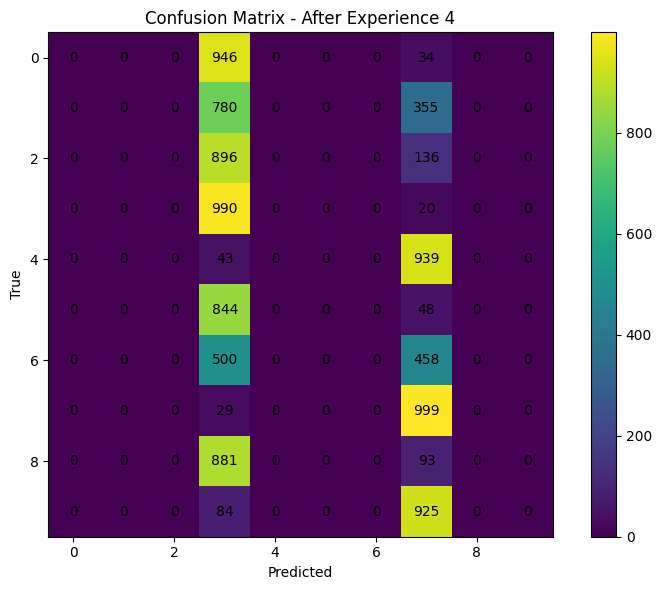

In [30]:
results_df = analyze_single_experiment(results, display_fn=display)


================ PLOTTING RESULTS ================

1. All accuracy curves


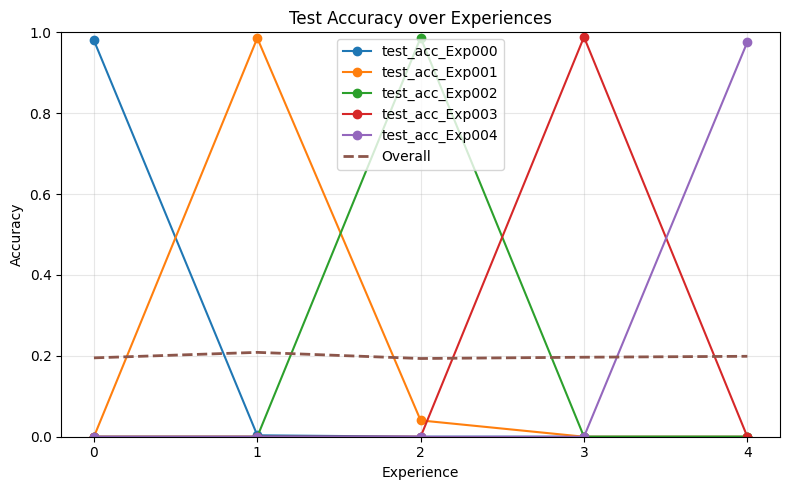

2. All forgetting curves


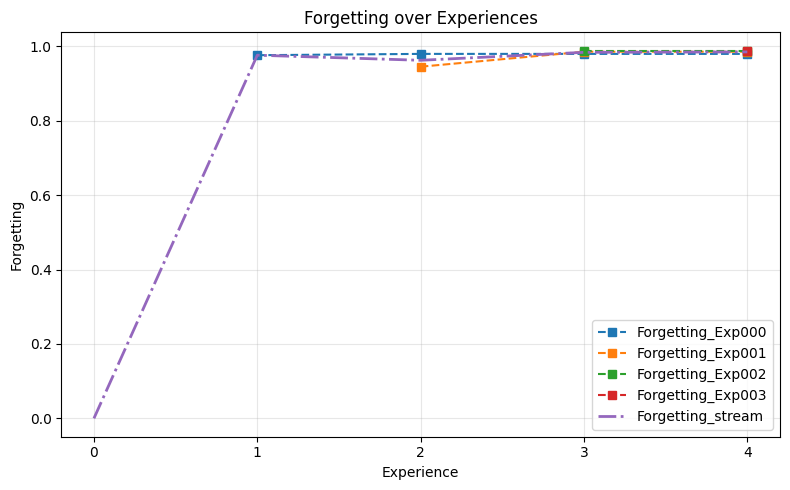

3. Per-task accuracy + forgetting plots


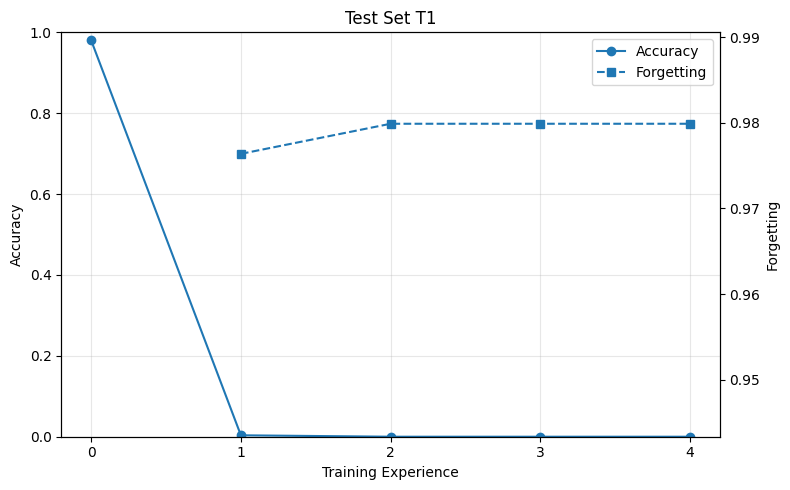

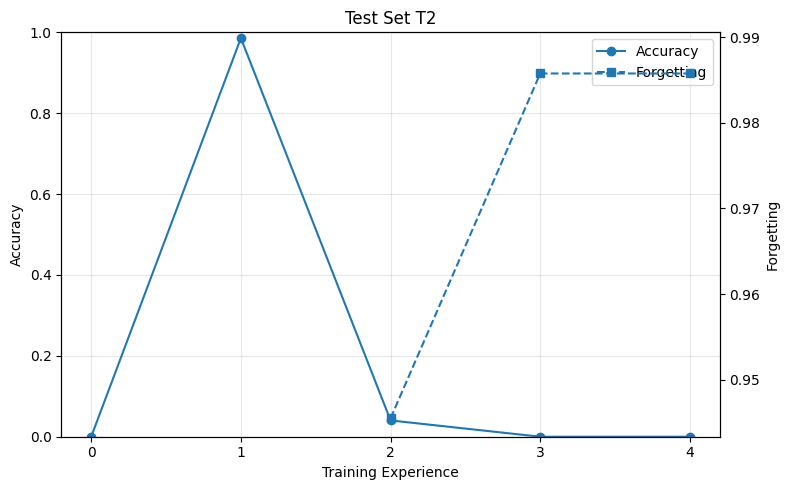

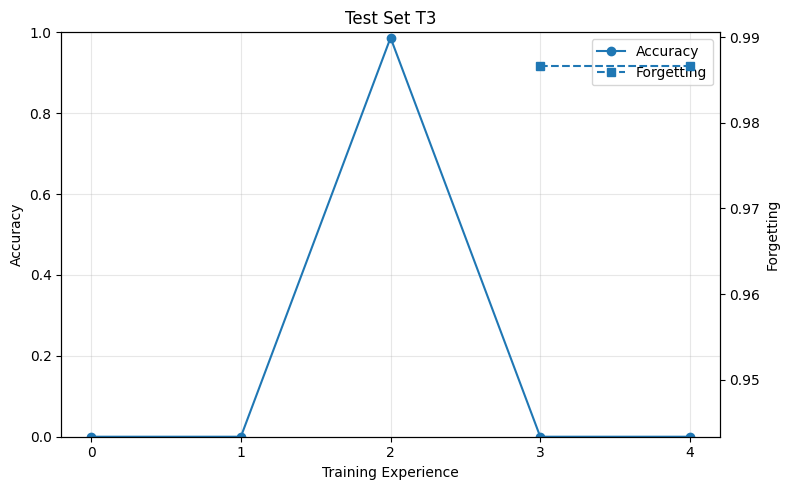

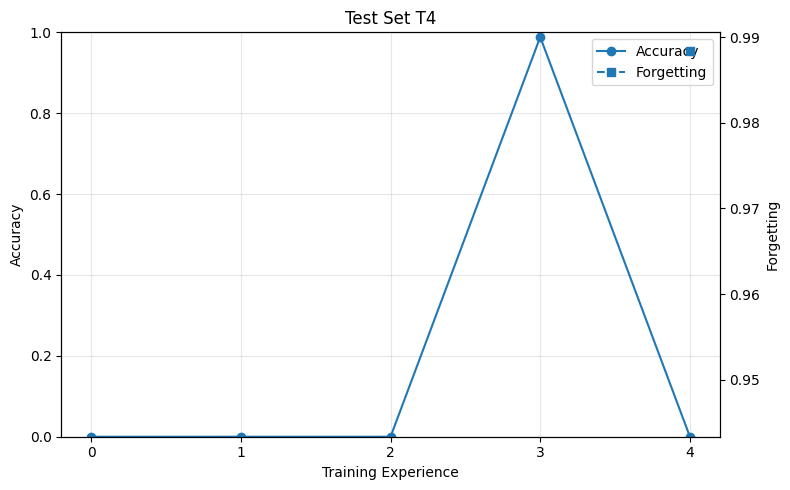

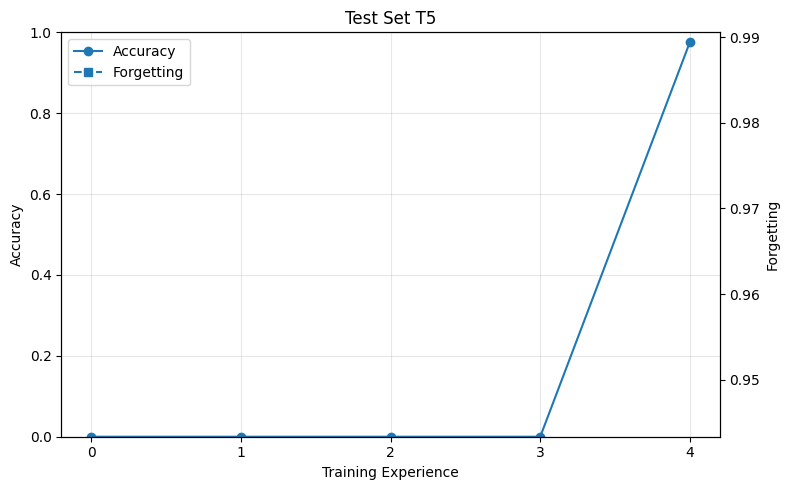

4. Raw summary bar plot

================ SINGLE MODEL BAR PLOT METRICS ================

Stream Accuracy: 0.198900
Stream Loss: 6.962157
Stream BWT: -0.985193
Stream FWT: 0.000000
Stream Forgetting: 0.985193
Avg Task Accuracy: 0.195191
Avg Task Forgetting: 0.985193
Avg Task BWT: -0.985193
Avg Task FWT: 0.000000
Avg Epoch Time: 5.414586


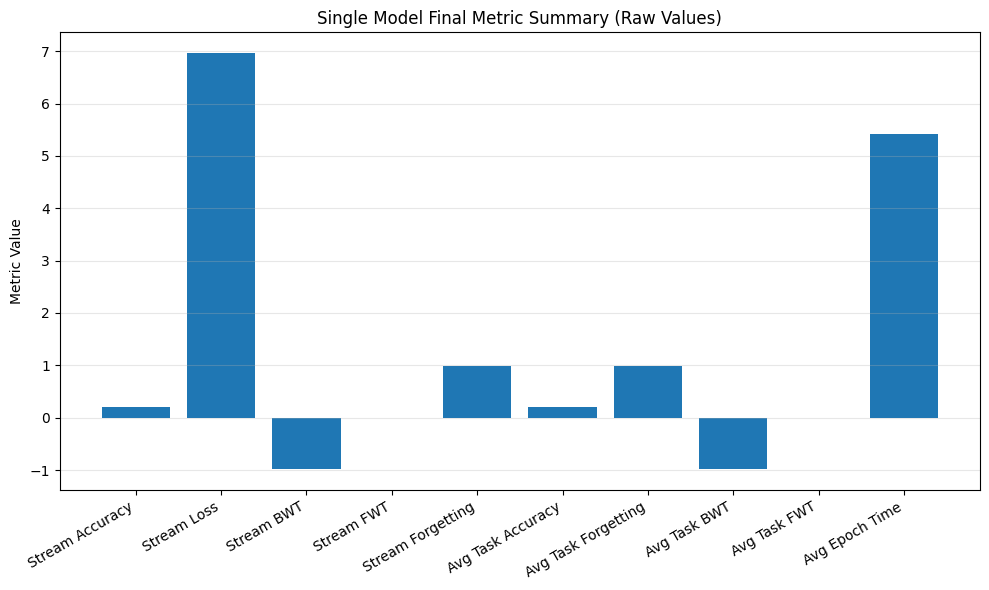

5. Normalized summary bar plot

================ SINGLE MODEL BAR PLOT METRICS ================

Stream Accuracy: 0.198900
Stream Loss: 0.000000
Stream BWT: 0.007404
Stream FWT: 0.500000
Stream Forgetting: 0.014807
Avg Task Accuracy: 0.195191
Avg Task Forgetting: 0.014807
Avg Task BWT: 0.007404
Avg Task FWT: 0.500000
Avg Epoch Time: 0.155895


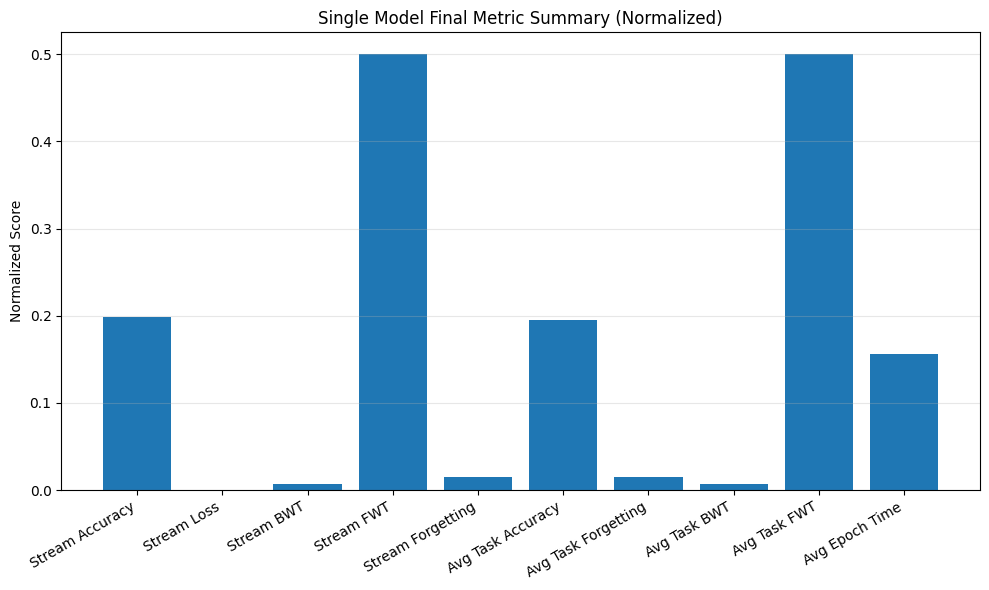

6. Spider plot

================ SINGLE MODEL SPIDER PLOT METRICS ================

Spider plot uses normalized scores so all metrics fit on one common scale.
For loss / forgetting / time, lower raw values become higher normalized scores.

Stream Accuracy: 0.198900
Stream Loss: 0.000000
Stream BWT: 0.007404
Stream FWT: 0.500000
Stream Forgetting: 0.014807
Avg Task Accuracy: 0.195191
Avg Task Forgetting: 0.014807
Avg Task BWT: 0.007404
Avg Task FWT: 0.500000
Avg Epoch Time: 0.155895


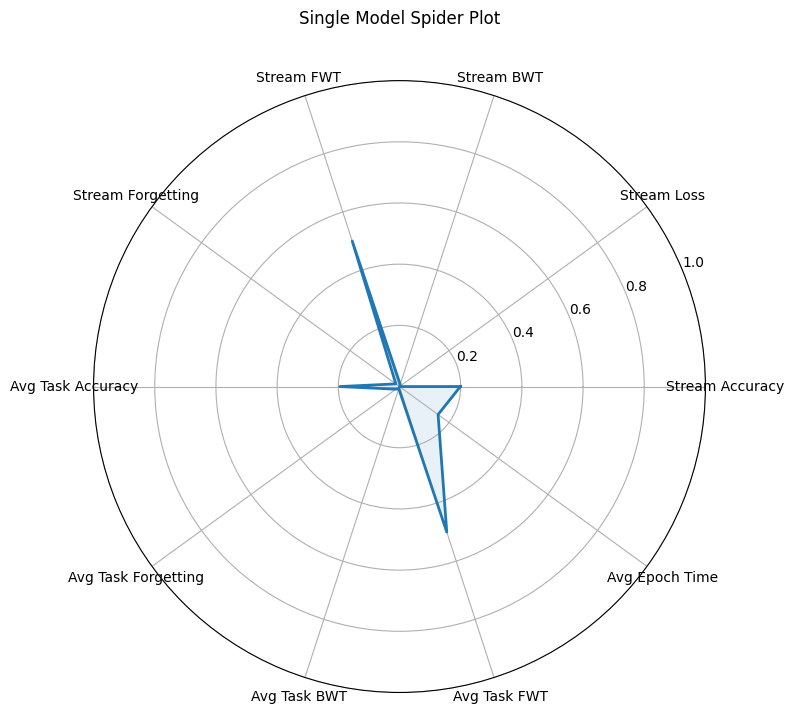


Done.



In [31]:
plot_single_experiment(results_df)

In [32]:
display(results_df.head())
print("Shape:", results_df.shape)
print("Columns:")
for c in results_df.columns:
    print("-", c)

,experience,train_time_epoch,test_acc_Exp000,test_loss_Exp000,cpu_usage_Exp000,test_disk_Exp000,test_acc_Exp001,test_loss_Exp001,cpu_usage_Exp001,test_disk_Exp001,...,BWT_Exp000,FWT_Exp002,Forgetting_Exp001,BWT_Exp001,FWT_Exp003,Forgetting_Exp002,BWT_Exp002,FWT_Exp004,Forgetting_Exp003,BWT_Exp003
0,0,5.250972,0.979899,0.052004,175.010247,226.497070,0.000000,7.754761,178.352122,226.841797,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,5.690505,0.003518,5.713753,181.056233,351.545898,0.985775,0.047059,181.666491,352.073242,...,-0.976382,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,4.991304,0.000000,8.749817,181.584266,466.709961,0.040303,6.316499,181.485902,467.237305,...,-0.979899,0.0,0.945472,-0.945472,0.0,NaN,NaN,NaN,NaN,NaN
3,3,5.574412,0.000000,7.795127,173.253969,586.622070,0.000000,6.122878,176.676865,587.149414,...,-0.979899,0.0,0.985775,-0.985775,0.0,0.98666,-0.98666,0.0,NaN,NaN
4,4,5.565736,0.000000,9.156203,179.786183,710.551758,0.000000,8.412423,179.502481,711.079102,...,-0.979899,0.0,0.985775,-0.985775,0.0,0.98666,-0.98666,0.0,0.988436,-0.988436


Shape: (5, 41)
Columns:
- experience
- train_time_epoch
- test_acc_Exp000
- test_loss_Exp000
- cpu_usage_Exp000
- test_disk_Exp000
- test_acc_Exp001
- test_loss_Exp001
- cpu_usage_Exp001
- test_disk_Exp001
- test_acc_Exp002
- test_loss_Exp002
- cpu_usage_Exp002
- test_disk_Exp002
- test_acc_Exp003
- test_loss_Exp003
- cpu_usage_Exp003
- test_disk_Exp003
- test_acc_Exp004
- test_loss_Exp004
- cpu_usage_Exp004
- test_disk_Exp004
- test_acc_stream
- test_loss_stream
- Forgetting_stream
- BWT_stream
- FWT_Exp001
- FWT_stream
- test_disk_stream
- confusion_matrix
- Forgetting_Exp000
- BWT_Exp000
- FWT_Exp002
- Forgetting_Exp001
- BWT_Exp001
- FWT_Exp003
- Forgetting_Exp002
- BWT_Exp002
- FWT_Exp004
- Forgetting_Exp003
- BWT_Exp003


In [33]:
results_df.to_csv(f"{output_dir}/results_df.csv", index=False)
print("Saved results_df.csv")

Saved results_df.csv
